In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ========================================================
# Ripple Edge Detection Pipeline
# ========================================================

def preprocess_for_ripple(gray):
    denoised = cv2.bilateralFilter(gray, d=7, sigmaColor=50, sigmaSpace=50)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(denoised)
    return enhanced


def percentile_canny(gray, low_pct=75, high_pct=92):
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx ** 2 + gy ** 2)
    low = np.percentile(mag, low_pct)
    high = np.percentile(mag, high_pct)
    edges = cv2.Canny(gray, int(low), int(high))
    return edges


def remove_small_components(edge_map, min_area=25):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(edge_map, 8)
    cleaned = np.zeros_like(edge_map)
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cleaned[labels == i] = 255
    return cleaned


def detect_ripple_edges(frame, water_mask=None):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    if water_mask is not None:
        gray = gray * water_mask
    enhanced = preprocess_for_ripple(gray)
    edges = percentile_canny(enhanced, low_pct=75, high_pct=92)
    if water_mask is not None:
        edges = edges * water_mask
    cleaned = remove_small_components(edges, min_area=25)
    return cleaned

print("Functions loaded.")


Functions loaded.


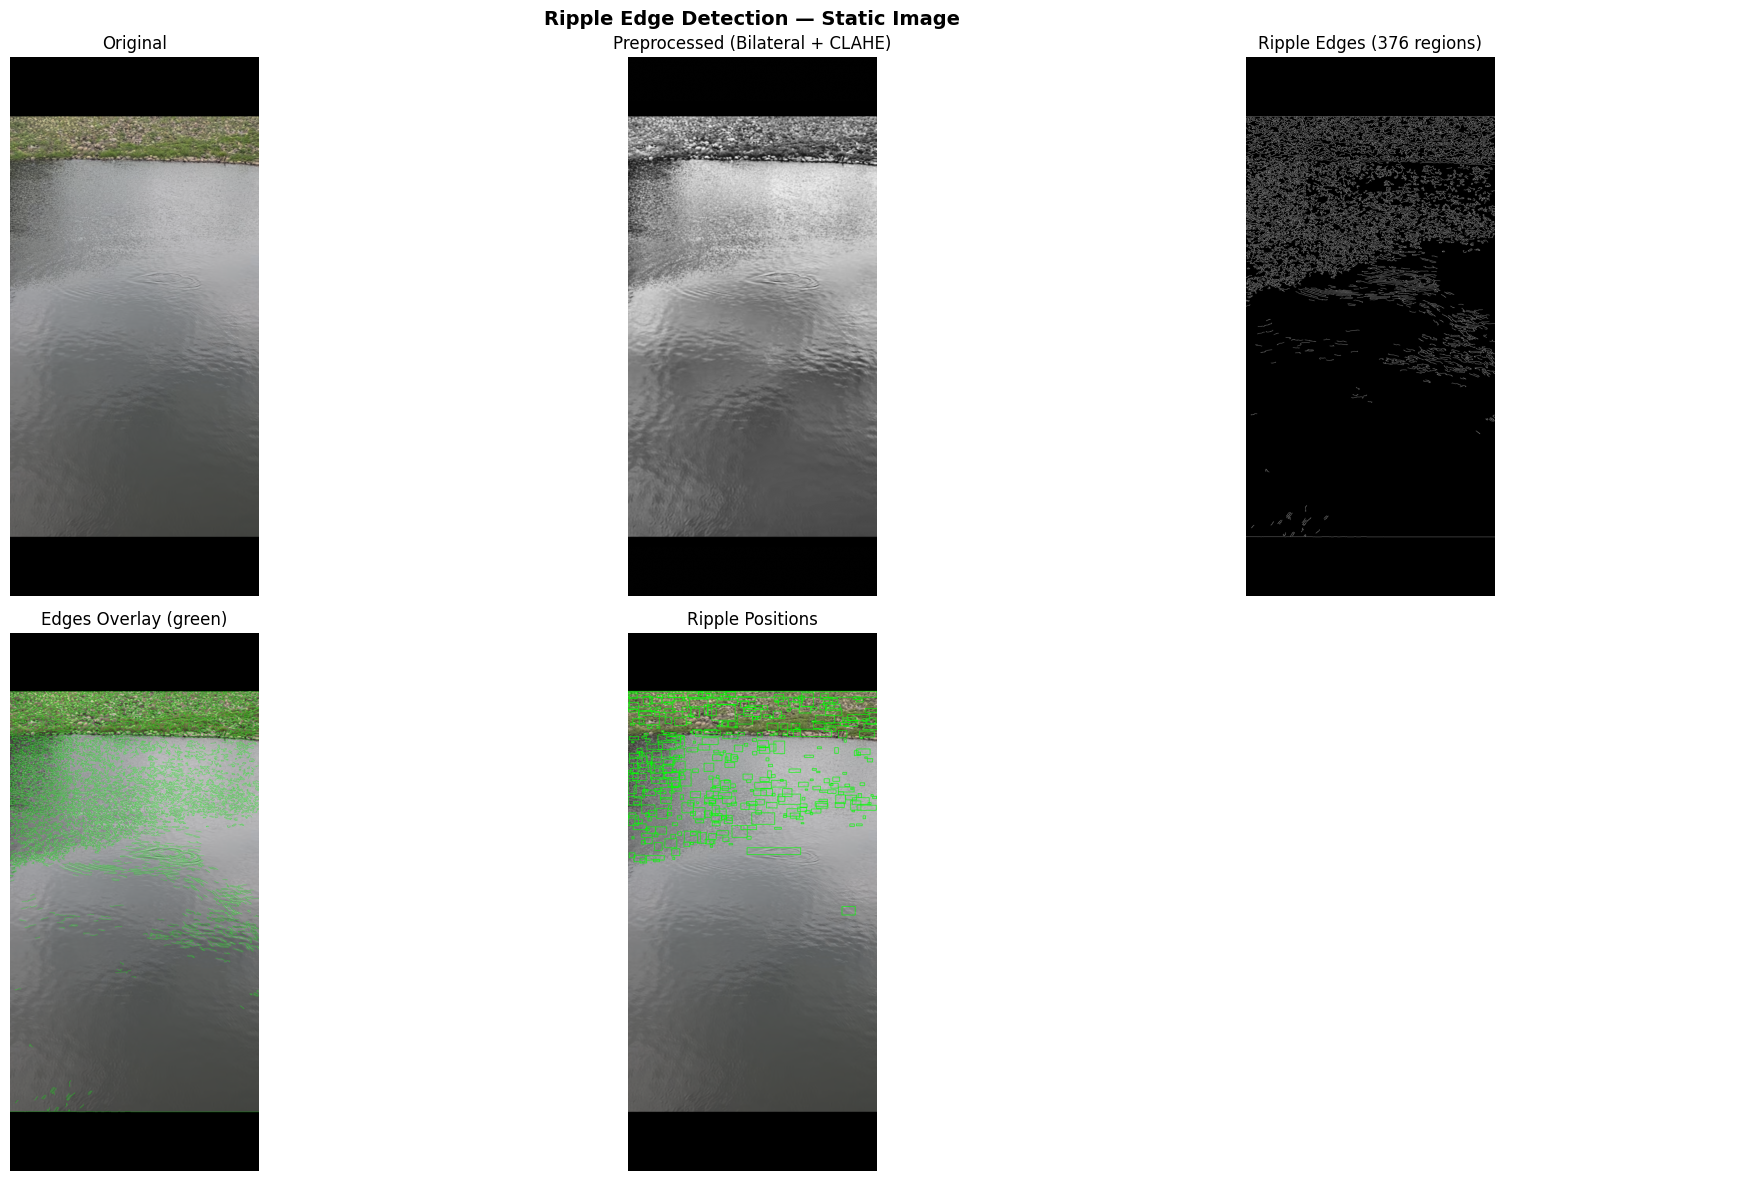


Found 376 ripple regions:
   1. pos=(1005,1289)  size= 62x 40
   2. pos=( 119,1067)  size= 29x 12
   3. pos=(  56,1066)  size= 31x 19
   4. pos=( 210,1057)  size=  9x 12
   5. pos=(  86,1050)  size= 84x 21
   6. pos=(  28,1048)  size= 52x 31
   7. pos=(   5,1037)  size= 27x 23
   8. pos=( 205,1018)  size= 38x 32
   9. pos=( 559,1013)  size=252x 32
  10. pos=( 386, 998)  size= 11x 14
  11. pos=( 474, 993)  size= 17x  7
  12. pos=( 293, 989)  size= 13x  9
  13. pos=( 124, 989)  size= 36x 36
  14. pos=( 262, 986)  size= 28x 22
  15. pos=( 384, 981)  size= 18x 14


In [2]:
# ========================================================
# Static Image Analysis
# ========================================================
pic = cv2.imread("../data/ripple1.PNG")
ripple_edges = detect_ripple_edges(pic)
gray = cv2.cvtColor(pic, cv2.COLOR_BGR2GRAY)
enhanced = preprocess_for_ripple(gray)

# Find ripple contours & positions
contours, _ = cv2.findContours(ripple_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
ripple_positions = []
pos_frame = pic.copy()
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    if cv2.contourArea(cnt) > 30:
        ripple_positions.append((x, y, w, h))
        cv2.rectangle(pos_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

# Overlay edges on original
edge_overlay = pic.copy()
edge_overlay[ripple_edges > 0] = (0, 255, 0)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

axes[0, 0].imshow(cv2.cvtColor(pic, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

axes[0, 1].imshow(enhanced, cmap="gray")
axes[0, 1].set_title("Preprocessed (Bilateral + CLAHE)")
axes[0, 1].axis("off")

axes[0, 2].imshow(ripple_edges, cmap="gray")
axes[0, 2].set_title(f"Ripple Edges ({len(ripple_positions)} regions)")
axes[0, 2].axis("off")

axes[1, 0].imshow(cv2.cvtColor(edge_overlay, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Edges Overlay (green)")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.cvtColor(pos_frame, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Ripple Positions")
axes[1, 1].axis("off")

axes[1, 2].axis("off")

plt.suptitle("Ripple Edge Detection — Static Image", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nFound {len(ripple_positions)} ripple regions:")
for i, (x, y, w, h) in enumerate(ripple_positions[:15]):
    print(f"  {i+1:2d}. pos=({x:4d},{y:4d})  size={w:3d}x{h:3d}")


Video: 298 frames, 1920x1080 @ 29.0 FPS

  50/298 frames  |  regions=317  edge%=6.36%
  100/298 frames  |  regions=355  edge%=5.73%
  150/298 frames  |  regions=330  edge%=5.74%
  200/298 frames  |  regions=418  edge%=6.08%
  250/298 frames  |  regions=412  edge%=6.45%

Output: ../data/ripple_edges_output.mp4 (289 frames)



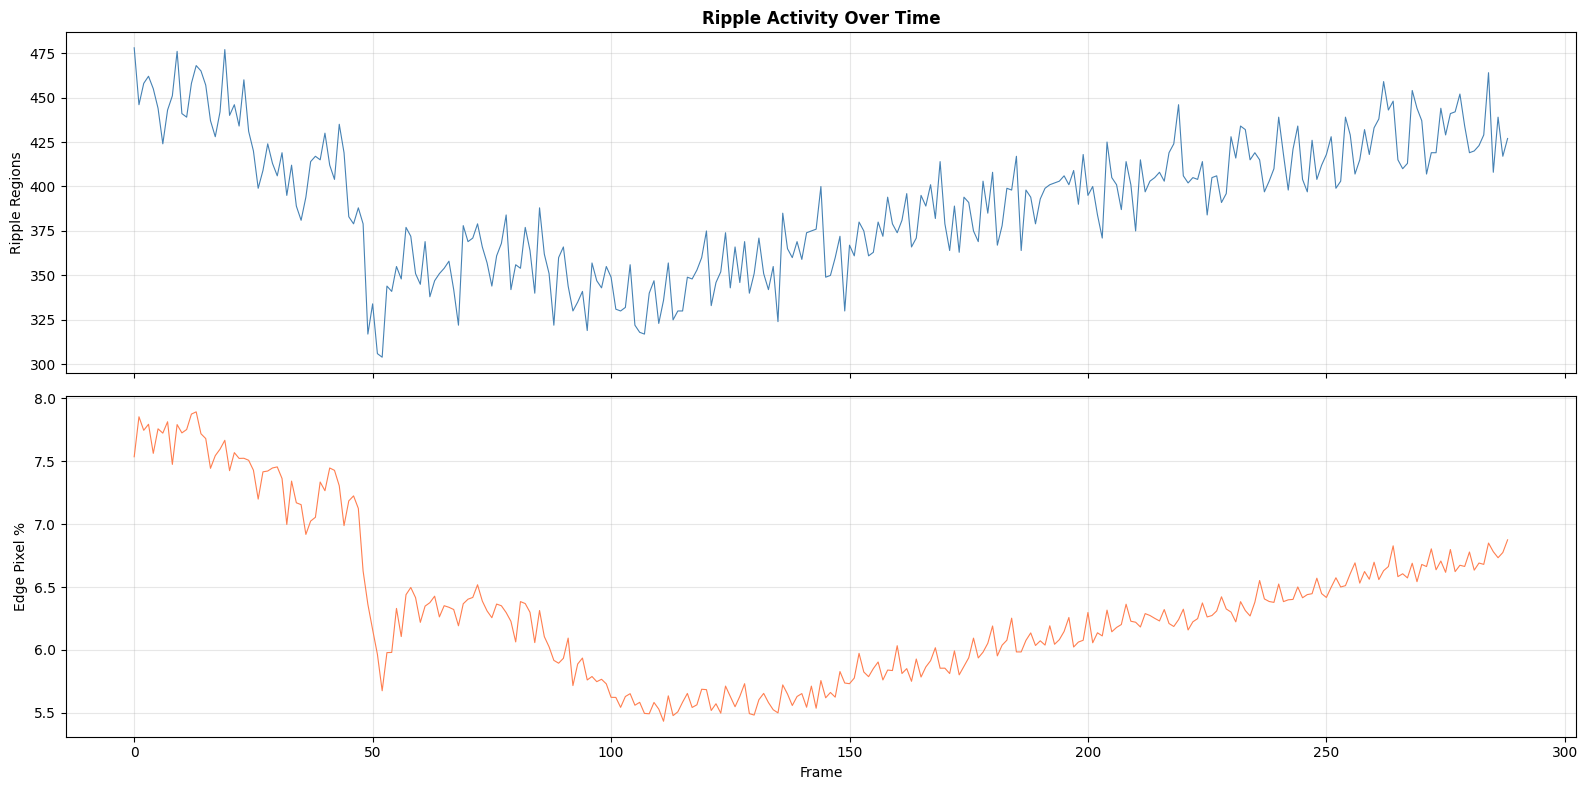

Mean regions per frame: 390.6
Peak regions: 478 at frame 0
Mean edge coverage: 6.34%


In [ ]:
# ========================================================
# Video Analysis
# ========================================================
from IPython.display import Video, display

cap = cv2.VideoCapture("../data/fish_ripple.mov")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"Video: {total_frames} frames, {w}x{h} @ {fps:.1f} FPS\n")

# Output video: original | edges overlay | edges binary
out_path = "../data/ripple_edges_output.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_w = w * 3
out = cv2.VideoWriter(out_path, fourcc, fps, (out_w, h))

frame_count = 0
ripple_stats = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    edges = detect_ripple_edges(frame)

    # Edge overlay
    overlay = frame.copy()
    overlay[edges > 0] = (0, 255, 0)

    # 3-channel edges for stacking
    edges_bgr = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

    # Info
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    valid = [c for c in contours if cv2.contourArea(c) > 30]
    edge_pct = np.sum(edges > 0) / edges.size * 100

    cv2.putText(frame, f"Frame {frame_count}", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    cv2.putText(overlay, f"{len(valid)} regions | {edge_pct:.2f}% edges", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    combined = np.hstack((frame, overlay, edges_bgr))
    out.write(combined)

    ripple_stats.append((frame_count, len(valid), edge_pct))
    frame_count += 1

    if frame_count % 50 == 0:
        est = total_frames / frame_count
        print(f"  {frame_count}/{total_frames} frames  |  regions={len(valid)}  edge%={edge_pct:.2f}%")

cap.release()
out.release()
print(f"\nOutput: {out_path} ({frame_count} frames)\n")

# Ripple activity over time
frames, regions, edge_pcts = zip(*ripple_stats)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
ax1.plot(frames, regions, color="steelblue", linewidth=0.8)
ax1.set_ylabel("Ripple Regions")
ax1.set_title("Ripple Activity Over Time", fontsize=12, fontweight="bold")
ax1.grid(True, alpha=0.3)

ax2.plot(frames, edge_pcts, color="coral", linewidth=0.8)
ax2.set_xlabel("Frame")
ax2.set_ylabel("Edge Pixel %")
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mean regions per frame: {np.mean(regions):.1f}")
print(f"Peak regions: {np.max(regions)} at frame {frames[np.argmax(regions)]}")
print(f"Mean edge coverage: {np.mean(edge_pcts):.2f}%")

# Show output video
display(Video(out_path, width=out_w // 2, embed=True))
